# 2.1.- Regresión Lineal OLS

La **regresión lineal** es un modelo estadístico utilizado para estudiar la relación entre una variable independiente $x$ y una variable dependiente $y$.

La ecuación de una recta es:

$$\large \hat{y} = \beta_1 x + \beta_0$$

donde:

* $\beta_1$ = pendiente (indica cuánto cambia $y$ cuando $x$ aumenta en una unidad).
* $\beta_0$ = intercepto (indica el valor de $y$ cuando $x=0$).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## Datos de ejemplo: [Anscombe's quartet](https://es.wikipedia.org/wiki/Cuarteto_de_Anscombe)

Para ilustrae La Regresión LinealS)**, usaremos un conjunto de datos clásico: el **Cuarteto de Anscombe**.  

Este dataset muestra cómo **diferentes distribuciones de datos pueden tener las mismas estadísticas descriptivas (media, varianza, correlación, regresión lineal)**, pero comportarse de forma muy distinta al graficarlos.

Trabajaremos con el primer grupo de datos $(x, y)$.

In [ ]:
# Cargar dataset de Anscombe quintet
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Definimos las variables de interés
df["x"] = df["x1235"]
df["y"] = df["y1"]

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95


## Visualización de los datos

Antes de ajustar el modelo de regresión, es fundamental **explorar gráficamente los datos**.  

Usaremos un gráfico de dispersión (*scatter plot*) con [Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html):

* Eje $x$: variable independiente.
* Eje $y$: variable dependiente.
* Cada punto $(x_i, y_i)$ representa una observación del ataset.


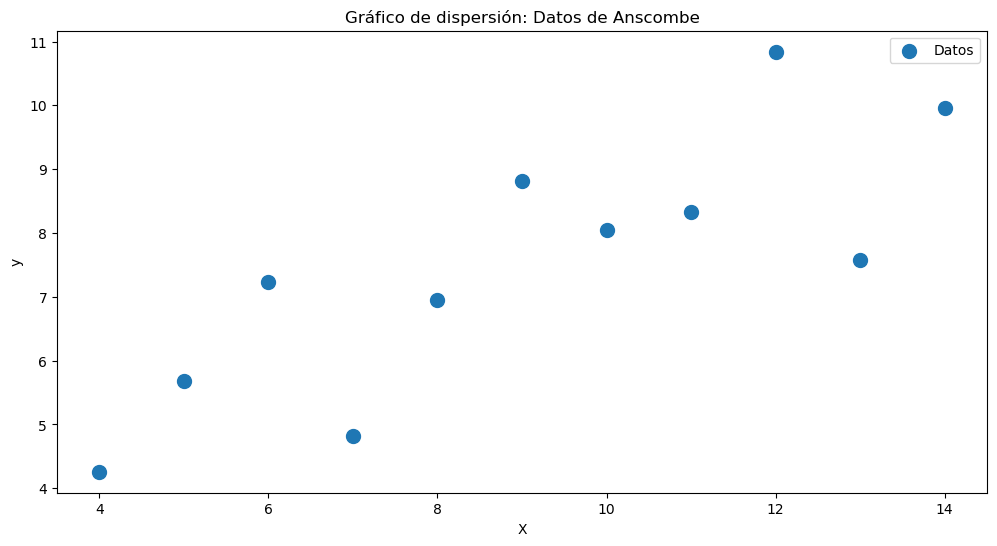

In [ ]:
fig = plt.figure(figsize=(12, 6))
plt.scatter(df["x"], df["y"], s=100, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Gráfico de dispersión: Datos de Anscombe")
plt.legend()
plt.show()

## [Mínimos Cuadrados Ordinarios](https://es.wikipedia.org/wiki/M%C3%ADnimos_cuadrados) (OLS)

El objetivo de OLS es encontrar la recta que mejor ajusta los datos, minimizando la suma de los errores al cuadrado.  

Ecuación de la recta:

$$\large \hat{y} = \beta_1 x + \beta_0$$

Las fórmulas de OLS son:

Para la pendiente $\beta_1$:

$$\large \beta_1 = \frac{ \sum \left( (x_i - \overline{x}) (y_i - \overline{y}) \right) } {\sum  (x_i - \overline{x})^2}$$

Para el intercepto $\beta_0$:

$$\large \beta_0 = \overline{y} - \beta_1 \overline{x}$$

---

Funciones útiles en Python:

* [`np.mean(x)`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) → calcula la media.
* [`np.sum(x)`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) → suma todos los elementos.
* `x**2` → eleva al cuadrado cada elemento.

In [ ]:
# Extraer las variables
x = df["x"].values
y = df["y"].values

# Medias
x_mean = np.mean(x)
y_mean = np.mean(y)

# Fórmulas OLS
beta_1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
beta_0 = y_mean - beta_1 * x_mean

print("Pendiente (beta_1):", beta_1)
print("Intercepto (beta_0):", beta_0)

Pendiente (beta_1): 0.5000909090909091
Intercepto (beta_0): 3.0000909090909076


## Interpretación de los coeficientes

Con el cálculo anterior hemos obtenido:

* $\beta_1$ = pendiente → cuánto aumenta (o disminuye) $y$ cuando $x$ crece en una unidad.
* $\beta_0$ = intercepto → valor de $y$ cuando $x = 0$.

## Recta ajustada a los datos

Con los coeficientes $\beta_0$ y $\beta_1$, podemos calcular los valores predichos $\hat{y}$ para cada observación $x_i$:

$$\large \hat{y}_i = \beta_1 x_i + \beta_0$$

Estos valores $\hat{y}$ se añaden a nuestro DataFrame como una nueva columna **`y_pred`**, que representa la recta de regresión ajutada.


In [ ]:
# Calcular valores predichos y guardarlos en el DataFrame
df["y_pred"] = beta_1 * df["x"] + beta_0

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y,y_pred
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26,5.000455
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68,5.500545
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24,6.000636
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82,6.500727
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95,7.000818


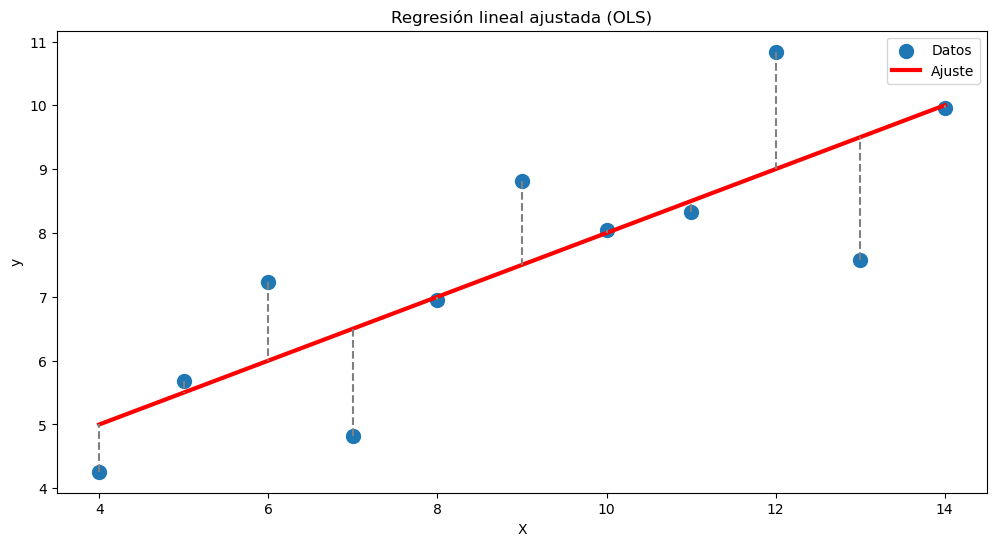

In [ ]:
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Recta ajustada
plt.plot(df["x"], df["y_pred"], color="red", lw=3, label="Ajuste")

# Líneas verticales = residuos (y - y_pred)
for i in range(len(df)):
    plt.plot([df["x"].iloc[i], df["x"].iloc[i]],
             [df["y"].iloc[i], df["y_pred"].iloc[i]],
             color="gray", linestyle="--")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión lineal ajustada (OLS)")
plt.legend()
plt.show()

## Usando álgebra lineal y la [ecuación normal](http://mlwiki.org/index.php/Normal_Equation)

Podemos tratar el problema de la regresión lineal como un [sistema de ecuaciones lineales](https://es.wikipedia.org/wiki/Sistema_de_ecuaciones_lineales):

$$\large X \beta = y $$

donde $\beta$ es el vector de coeficientes.  
Por ejemplo, para la primera observación:

$$\large \beta_1 (x_1)^1 + \beta_0 (x_1)^0 = y_1 $$

---

Esto se puede escribir en forma matricial:

$$ X^T X \beta = X^T y $$

y resolviendo para $\beta$ obtenemos:

$$ \beta = (X^T X)^{-1} X^T y $$

---

Notas útiles:

* $X^T$ es la [traspuesta de una matriz](https://es.wikipedia.org/wiki/Traspuesta) (en Python: `.T`).  
* La inversa de una matriz se calcula con [`numpy.linalg.inv`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.inv.html).  


In [ ]:
# Construcción de la matriz de diseño: [x, 1]
X1 = np.column_stack((np.ones(len(df)), df["x"]))

# Vector de salida
y_vec = df["y"].values

# Aplicamos la ecuación normal
betas = np.linalg.inv(X1.T @ X1) @ X1.T @ y_vec

print("Pendiente (beta_1):", betas[1])
print("Intercepto (beta_0):", betas[0])

Pendiente (beta_1): 0.5000909090909094
Intercepto (beta_0): 3.000090909090904


# 2.2.- Regresión Polinómica OLS

La **regresión polinómica** es una técnica que extiende la regresión lineal al permitir que el modelo se ajuste a relaciones no lineales entre las variables independientes y la variable dependiente.

### Idea principal:
- En regresión lineal simple, el modelo es:
  
  $$
  \hat{y} = \beta_0 + \beta_1 x
  $$

- En regresión polinómica de grado $d$, se incluyen potencias de $x$:

  $$
  \hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \cdots + \beta_d x^d
  $$

### Ventajas:
- Permite capturar relaciones curvas o más complejas.
- Se puede usar con una sola variable (regresión polinómica simple) o con varias (regresión polinómica múltiple).

### Inconvenientes:
- Un grado muy alto del polinomio puede producir **sobreajuste**: el modelo se ajusta demasiado al ruido de los datos en lugar de a la tendencia general.
- A mayor grado, mayor complejidad y peor interpretabilidad de los coeficientes.

---

En este notebook usaremos los datos del **conjunto 2 de Anscombe**.  
Este conjunto de datos muestra una relación **claramente no lineal** entre `x` e `y`.  
Veremos cómo una regresión lineal simple no logra capturar la curva y cómo la regresión polinómica mejora el ajuste.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [ ]:
# Cargar dataset de Anscombe quintet
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Seleccionamos el set 2 (que tiene una relación más curva)
df["x"] = df["x1235"]
df["y"] = df["y2"]

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,3.10
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,4.74
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,6.13
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,7.26
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,8.14


## Regresión lineal simple en Anscombe (set 2)

Ajustamos una recta de regresión lineal a los datos del **set 2 de Anscombe**.  
Como veremos, la línea recta no es capaz de capturar adecuadamente la relación curva entre `x` e `y`.

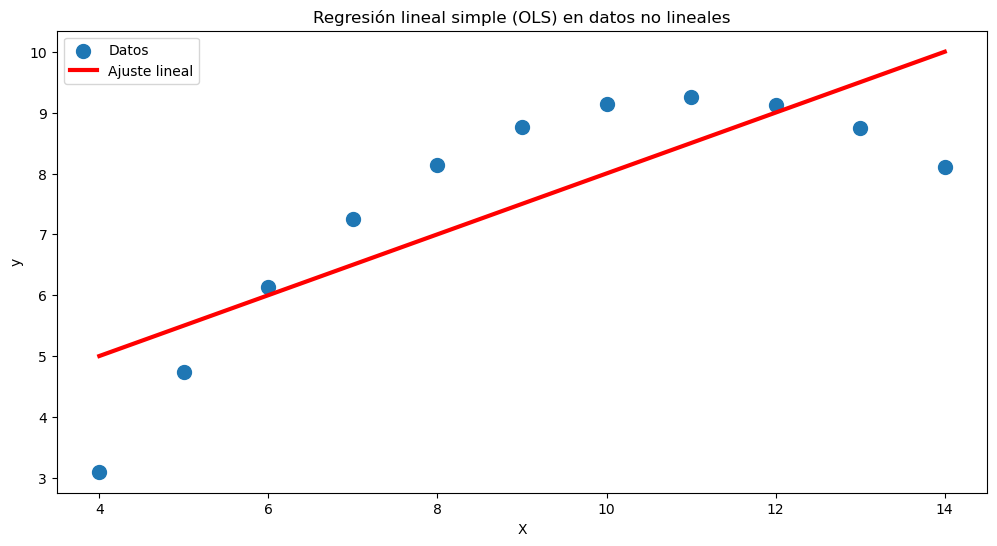

In [ ]:
# Definir variables
X = sm.add_constant(df["x"])  # añade la constante (β0)
y = df["y"]

# Ajustar el modelo lineal simple
modelo_lineal = LinearRegression().fit(X, y)

# Predicciones
df["y_pred"] = modelo_lineal.predict(X)

# Visualización en formato estándar
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Recta ajustada
plt.plot(df["x"], df["y_pred"], color="red", lw=3, label="Ajuste lineal")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión lineal simple (OLS) en datos no lineales")
plt.legend()
plt.show()

## Regresión polinómica de grado 2

La regresión polinómica consiste en añadir potencias de la variable `x` como nuevas características.

Para grado 2, el modelo es:

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2
$$

- La variable $x^2$ permite capturar relaciones cuadráticas (curvas en forma de parábola).
- Seguimos usando una regresión lineal, pero **aplicada a las nuevas variables**: $x$ y $x^2$.
- Esto hace que el modelo gane flexibilidad y se ajuste mejor a datos no lineales.

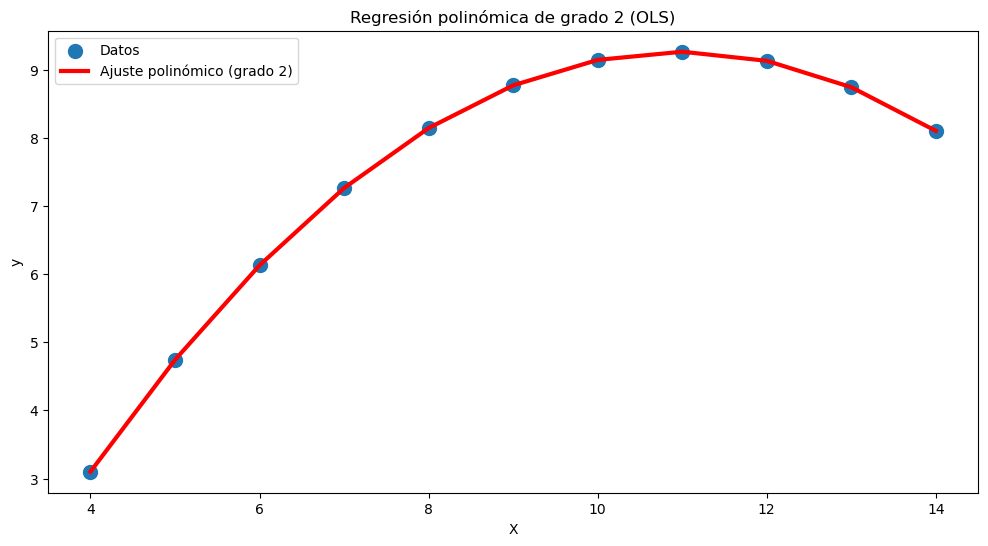

Intercepto (beta_0): -5.995734265734278
Pendiente (beta_1): 2.780839160839163
Coeficiente cuadrático (beta_2): -0.12671328671328683


In [ ]:
# Generar las nuevas características polinómicas (x y x^2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[["x"]])  # crea columnas: [x, x^2]

# Ajuste del modelo lineal sobre estas nuevas features
modelo_poly2 = LinearRegression().fit(X_poly, df["y"])

# Predicciones
df["y_pred_poly2"] = modelo_poly2.predict(X_poly)

# Visualización
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Curva ajustada (ordenada por x para que la curva salga suave)
plt.plot(df["x"], df["y_pred_poly2"], color="red", lw=3, label="Ajuste polinómico (grado 2)")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión polinómica de grado 2 (OLS)")
plt.legend()
plt.show()

# Coeficientes
print("Intercepto (beta_0):", modelo_poly2.intercept_)
print("Pendiente (beta_1):", modelo_poly2.coef_[0])
print("Coeficiente cuadrático (beta_2):", modelo_poly2.coef_[1])

## Interpretación de los coeficientes en regresión polinómica

El modelo ajustado de grado 2 es:

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2
$$

- **Intercepto ($\beta_0$):**  
  Valor de $\hat{y}$ cuando $x = 0$. Representa el punto de corte con el eje $y$.

- **Pendiente ($\beta_1$):**  
  Representa el cambio lineal de $y$ por cada unidad que aumenta $x$.  
  En este caso, no describe toda la tendencia, ya que existe curvatura.

- **Coeficiente cuadrático ($\beta_2$):**  
  Captura la **curvatura** de la relación.  
  - Si $\beta_2 > 0$, la curva se abre hacia arriba (forma de U).  
  - Si $\beta_2 < 0$, la curva se abre hacia abajo (forma de ∩).  

# 2.3.- Intervalos de Confianza y Escalado de Variables

Vamos a generar un conjunto de datos artificial siguiendo la ecuación:

$$ y = 2x + 5 + \varepsilon $$

donde:
- $\varepsilon \sim N(0, 3)$ es un término de ruido gaus
- siano.  
- Esto simula un escenario real: la relación entre $x$ e $y$ es lineal, pero con cierta variabilidad aleatoria.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
# Semilla para reproducibilidad
np.random.seed(33)

# Generamos datos lineales con ruido gaussiano
x = np.linspace(0, 10, 50)
y = 2 * x + 5 + np.random.normal(0, 3, size=len(x))

# Guardamos en un DataFrame
df = pd.DataFrame({"x": x, "y": y})
df.sample(5)  # muestra aleatoria de los datos

,x,y
49,10.000000,29.463009
17,3.469388,14.437695
23,4.693878,15.391156
19,3.877551,13.785490
20,4.081633,17.801356


## Ajuste del modelo OLS e intervalos de confianza

Usamos `statsmodels.OLS` para estimar los coeficientes de la regresión lineal:

$$ \hat{y} = \beta_0 + \beta_1 x $$

El resumen del modelo incluye:

- Los valores estimados de $\beta_0$ (intercepto) y $\beta_1$ (pendiente).
- Sus errores estándar.
- Los **intervalos de confianza (IC)** al 95% para cada coeficiente.

In [ ]:
# Añadimos la constante (columna de 1s para el intercepto)
X = sm.add_constant(df["x"])

# Ajustamos el modelo OLS
model = sm.OLS(df["y"], X).fit()

# Resumen del modelo con IC de los coeficientes
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     221.4
Date:                Tue, 23 Sep 2025   Prob (F-statistic):           1.32e-19
Time:                        15:17:06   Log-Likelihood:                -123.29
No. Observations:                  50   AIC:                             250.6
Df Residuals:                      48   BIC:                             254.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0097      0.810      4.949      0.000       2.381       5.639
x              2.0774      0.140     14.880      0.000       1.797       2.358
==============================================================================
Omnibus:                        0.871   Durbin-Watson:                   1.952
Prob(Omnibus):                  0.647   Jarque-Bera (JB):                0.897
Skew:                           0.290   Prob(JB):                        0.639
Kurtosis:                       2.695   Cond. No.                         11.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Visualización de la recta de regresión con intervalo de confianza (95%)

Podemos representar gráficamente:

- Los **puntos observados** (x, y).  
- La **recta ajustada** con OLS.  
- La **banda de confianza al 95%**, que muestra la incertidumbre del ajuste.

La banda se interpreta así:  
- Si repitiéramos el muestreo muchas veces, el 95% de las rectas ajustadas estarían dentro de esa franja.  
- Ojo: el IC no significa que el 95% de los datos estén dentro de la franja.

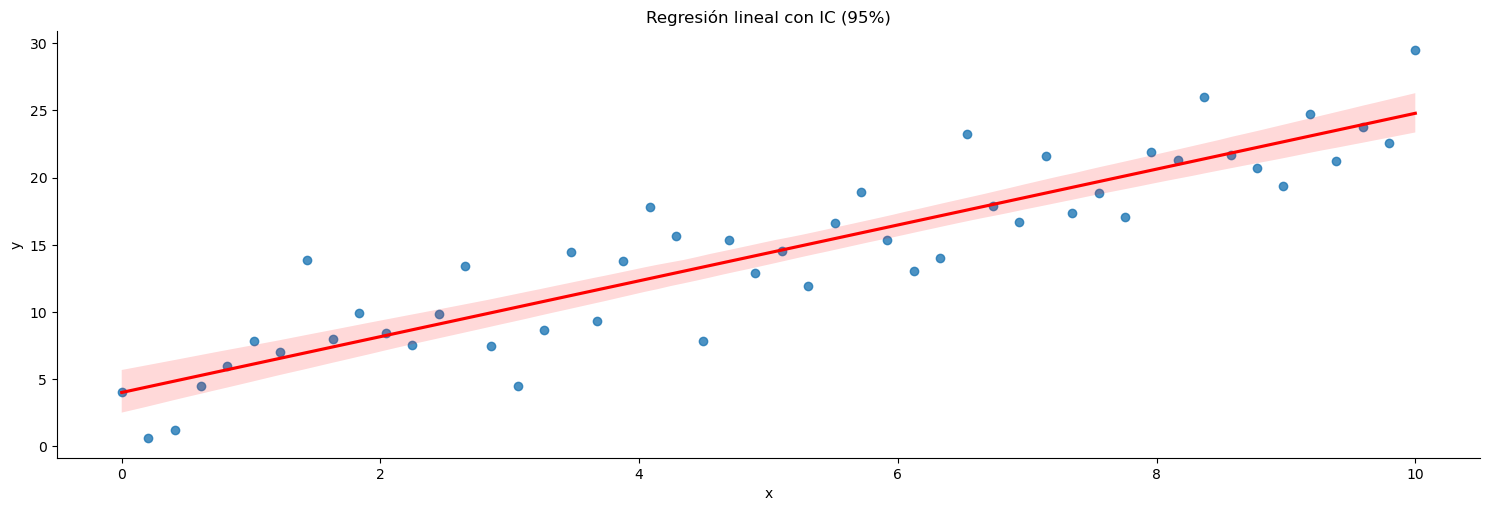

In [ ]:
# Gráfico de la regresión con banda de IC al 95%
sns.lmplot(x="x", y="y", data=df, ci=95, line_kws={"color": "red"}, height=5, aspect=3)
plt.title("Regresión lineal con IC (95%)")
plt.show()

## Escalado de variables con StandardScaler

En regresión y en otros algoritmos de Machine Learning es común **escalar las variables**.  

Motivación:
- Si las variables tienen órdenes de magnitud muy diferentes (ej. `metros` frente a `euros`),  
  los coeficientes pueden quedar desbalanceados.  
- En métodos iterativos como el **descenso del gradiente**, el escalado acelera y estabiliza la convergencia.  

El **StandardScaler** transforma cada variable de forma que tenga:
- **Media = 0**  
- **Desviación estándar = 1**

Esto facilita la comparación y el entrenamiento de los modelos.

In [ ]:
# Inicializamos el escalador
scaler = StandardScaler()

# Ajustamos y transformamos la variable x
X_scaled = scaler.fit_transform(df[["x"]])

# Comprobamos media y desviación estándar
print("Media escalada:", X_scaled.mean())
print("Desviación estándar:", X_scaled.std())

# Creamos un DataFrame con los valores originales y escalados
df_scaled = df.copy()
df_scaled["x_escalada"] = X_scaled

# Mostramos comparación
df_scaled.head(10)

Media escalada: 4.884981308350689e-17
Desviación estándar: 1.0


,x,y,x_escalada
0,0.000000,4.043439,-1.697749
1,0.204082,0.599222,-1.628453
2,0.408163,1.210673,-1.559158
3,0.612245,4.513287,-1.489862
4,0.816327,5.982468,-1.420566
5,1.020408,7.805439,-1.351270
6,1.224490,7.000630,-1.281974
7,1.428571,13.889491,-1.212678
8,1.632653,7.974954,-1.143382
9,1.836735,9.940074,-1.074086


# 2.4.- Regresión Lineal con Descenso de Gradiente

En esta práctica vamos a implementar la regresión lineal usando **descenso de gradiente (Gradient Descent, GD)**.  

Objetivos:
- Definir la función de coste (MSE).  
- Calcular el gradiente de los parámetros.  
- Implementar el algoritmo de descenso de gradiente.  
- Analizar el efecto de la tasa de aprendizaje (*learning rate*).  

Recordemos que, en lugar de usar la **ecuación normal**, aquí ajustamos los parámetros $\beta$ de forma iterativa hasta minimizar la función de coste.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

## Datos de ejemplo

Generamos un conjunto de datos lineales con ruido gaussiano para simular un caso real.

Ecuación generadora:

$$ y = 4x + 3 + \varepsilon, \quad \varepsilon \sim N(0, 2) $$

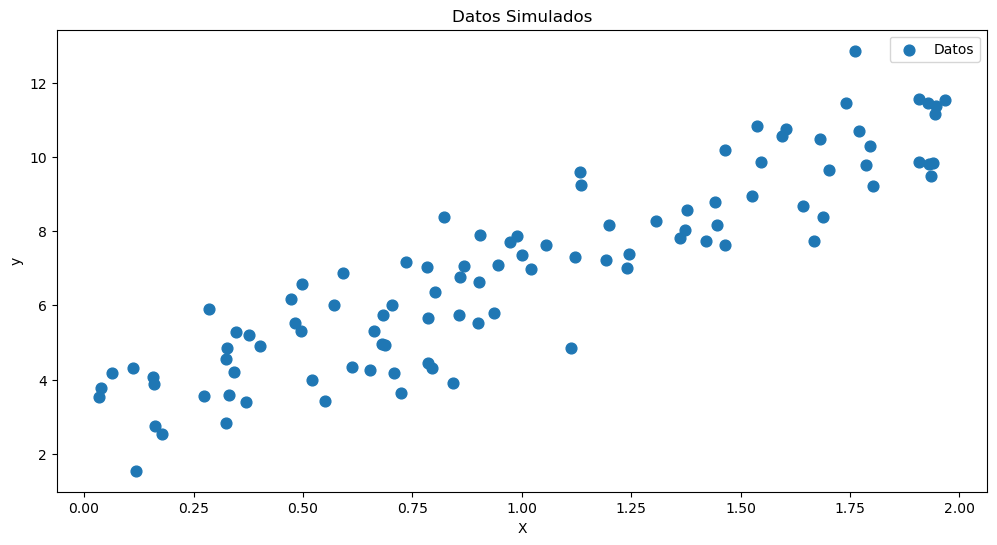

In [ ]:
# Semilla para reproducibilidad
np.random.seed(33)

# Generamos datos lineales con ruido
X = 2 * np.random.rand(100, 1)
y = 4 * X + 3 + np.random.randn(100, 1)

# Visualización
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=60, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Datos Simulados")
plt.legend()
plt.show()

## Función de coste: Error cuadrático medio (MSE)

La regresión lineal busca ajustar los parámetros $\beta_0, \beta_1$ de forma que las predicciones $\hat{y}$ sean lo más cercanas posibles a los valores reales $y$.

La medida de error más común es el **Error Cuadrático Medio (MSE)**:

$$
J = \frac{1}{n} \sum_{i=1}^{n} ( y_i - \hat{y}_i)^2
$$

donde:
- $n$ = número de observaciones.  
- $\hat{y}_i = \beta_0 + \beta_1 x_i$ son las predicciones.  
- $y_i$ son los valores observados.  

El objetivo del descenso de gradiente es **minimizar $J$**.

In [ ]:
# Definimos la función de coste MSE
def compute_cost(X, y, beta):
    """
    Calcula el Error Cuadrático Medio (MSE).

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta: parámetros [beta_0, beta_1]

    Devuelve:
        coste (float)
    """
    n = len(y)
    y_pred = X @ beta
    error = y - y_pred
    cost = (1/n) * np.sum(error**2)
    return cost

# Preparamos X con columna de 1s (intercepto)
X1 = sm.add_constant(X)  # añade columna de 1s
beta_inicial = np.zeros((2, 1))    # matriz de coeficientes: beta_0 = 0, beta_1 = 0

# Calculamos el coste inicial
coste_inicial = compute_cost(X1, y, beta_inicial)
print("Coste inicial (beta_0=0, beta_1=0):", coste_inicial)

Coste inicial (beta_0=0, beta_1=0): 54.97090132216898


## Gradiente de la función de coste

Para minimizar el MSE necesitamos calcular el **gradiente**, es decir, las derivadas parciales de $J(\beta)$ respecto a cada parámetro $\beta_j$.

Recordemos que:

$$
J(\beta) = \frac{1}{n} (X \beta - y)^T (X \beta - y)
$$

El gradiente viene dado por:

$$
\frac{\partial J(\beta)}{\partial \beta} = \frac{1}{n} X^T (X \beta - y)
$$

Esto nos indica en qué dirección (signo) y con qué magnitud debemos actualizar cada $\beta_j$ para acercarnos al mínimo de la fnción de coste.
te.

In [ ]:
def compute_gradient(X, y, beta):
    """
    Calcula el gradiente de la función de coste MSE.

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta: parámetros [beta_0, beta_1]

    Devuelve:
        gradiente (vector 2x1)
    """
    n = len(y)
    gradient = (1/n) * X.T @ (X @ beta - y)
    return gradient

# Gradiente con beta inicial (0,0)
gradiente_inicial = compute_gradient(X1, y, beta_inicial)
print("Gradiente inicial:", gradiente_inicial.ravel())

Gradiente inicial: [-6.95739967 -8.26540396]


## Algoritmo de descenso de gradiente

El algoritmo itera hasta encontrar los parámetros $\beta$ que minimizan la función de coste.

**Regla de actualización:**

$$
\beta \leftarrow \beta - \eta \cdot \frac{\partial J(\beta)}{\partial \beta}
$$

donde:
- $\eta$ es la **tasa de aprendizaje** (*learning rate*).  
- El término $\frac{\partial J(\beta)}{\partial \beta}$ es el gradiente.  

**Pasos del algoritmo:**
1. Elegir valores iniciales para $\beta$.  
2. Calcular el gradiente.  
3. Actualizar los parámetros usando la regla.  
4. Repetir hasta que $\beta$ apenas cambie o se alcance un número máximo de iteraciones.

In [ ]:
def gradient_descent(X, y, beta_inicial, learning_rate, n_iter):
    """
    Descenso de gradiente para regresión lineal.

    Parámetros:
        X: matriz de diseño
        y: vector de valores reales
        beta_inicial: valores iniciales de los parámetros
        learning_rate: tasa de aprendizaje (η)
        n_iter: número de iteraciones

    Devuelve:
        beta: parámetros optimizados
        history: lista con el valor del coste en cada iteración
    """
    beta = beta_inicial.copy()
    history = []

    for _ in range(n_iter):
        grad = compute_gradient(X, y, beta)
        beta -= learning_rate * grad
        history.append(compute_cost(X, y, beta))

    return beta, history

# Ejecutamos descenso de gradiente
beta_final, history = gradient_descent(X1, y, beta_inicial, learning_rate=0.1, n_iter=100)

print("Coeficientes finales:")
print("Intercepto (beta_0):", beta_final[0][0])
print("Pendiente (beta_1):", beta_final[1][0])

Coeficientes finales:
Intercepto (beta_0): 2.9591151363876698
Pendiente (beta_1): 4.014790483979907


## Evolución del coste durante el descenso de gradiente

Una forma de comprobar si el algoritmo está funcionando correctamente es observar la evolución del **MSE** a lo largo de las iteraciones.

- Si el learning rate $\eta$ es adecuado, el coste debe **disminuir rápidamente** y luego estabilizarse.  
- Si $\eta$ es demasiado pequeño, el descenso será muy lento.  
- Si $\eta$ es demasiado grande, el coste puede **oscilar o incluso divergir**.

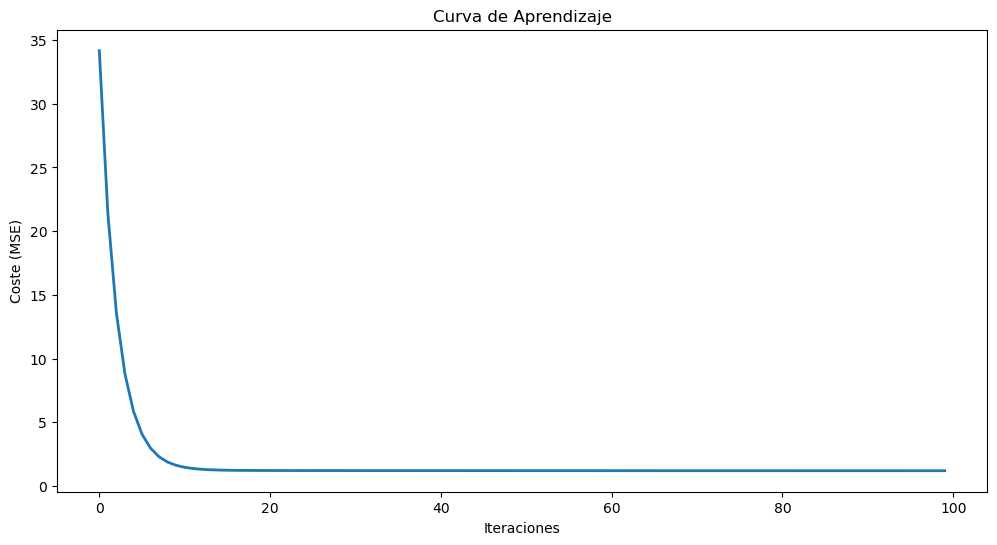

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(history, lw=2)
plt.xlabel("Iteraciones")
plt.ylabel("Coste (MSE)")
plt.title("Curva de Aprendizaje")
plt.show()

## Recta ajustada con los parámetros obtenidos mediante descenso de gradiente

Tras ejecutar el algoritmo, obtenemos los valores optimizados de $\beta_0$ y $\beta_1$.

Podemos representar la **recta ajustada** sobre los datos para comprobar visualmente la calidad del ajuste.

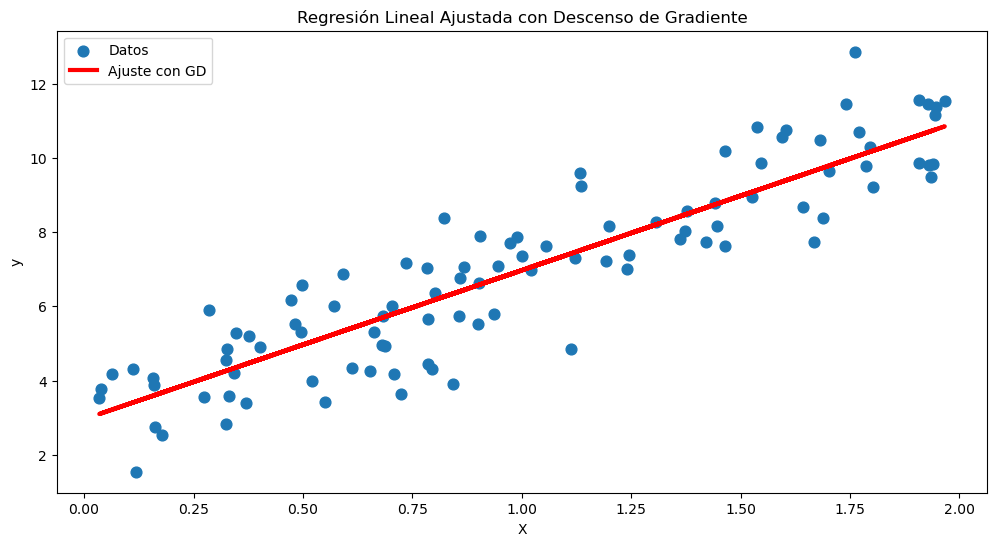

In [ ]:
# Predicciones usando los parámetros finales
y_pred = X1 @ beta_final

# Visualización
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=60, label="Datos")
plt.plot(X, y_pred, color="red", lw=3, label="Ajuste con GD")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión Lineal Ajustada con Descenso de Gradiente")
plt.legend()
plt.show()

---
### Interpretación de un modelo de regresión lineal

Un modelo estima el precio de una vivienda mediante:

```text
Precio 
= 40.000 + 2.000 · m² + 10.000 · habitaciones - 500 · antigüedad
```

La antigüedad se mide en años.

a) Interpreta cada coeficiente.

b) Estima el precio de una vivienda de 80 m², 3 habitaciones y 10 años.

c) ¿Podemos afirmar que añadir una habitación causa exactamente un aumento de 10.000 €?

In [ ]:
# a)
# b)
precio = 40000 + 2000 * 80 + 10000 * 3 - 500 * 10
print(precio, "€")
# c) Si

225000 €


### Regresión lineal y descenso del gradiente

**Modelo:** `y = β₀ + β₁x`

**Datos:** `(1, 3)` y `(2, 5)`.

Empezamos con `β₀ = 0`, `β₁ = 0` y una tasa de aprendizaje `η = 0.1`.

Usaremos la función de coste:

```text
J(β) = (1 / 2n) · Σ(ŷᵢ - yᵢ)²
```

De forma que el gradiente es:

```text
∇J = (1 / n) · Xᵀ(Xβ - y)
```

**Calcula una iteración del descenso del gradiente.**